# 03. PCA: главные компоненты

**Задача:** найти направление $v$ (рецепт портфеля длины 1), вдоль которого данные колеблются сильнее всего:
$$\max_v\; v^\top\Sigma v \quad \text{при}\quad v^\top v = 1$$
Лагранжиан $\mathcal L = v^\top\Sigma v - \lambda(v^\top v - 1)$, градиент $2\Sigma v - 2\lambda v = 0$:
$$\Sigma v = \lambda v, \qquad v^\top\Sigma v = \lambda$$
Собственный вектор — направление, собственное значение — дисперсия вдоль него. Σ симметрична и PSD, поэтому (спектральная теорема) $\Sigma = Q\Lambda Q^\top$, $Q^\top Q = I$, $\lambda_i \ge 0$.

**PCA — поворот осей:** в новых координатах факторы не коррелируют, а упорядочены по убыванию дисперсии.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.precision', 3)
from src.data import *
from src.risk import *
from src.pca import *
from src.plots import *

In [2]:
r = simple_returns(clean_prices(load_prices()))
S = covariance_matrix(r)
C = correlation_from_cov(S)

## Интуиция на двух активах
Каждая точка — день. PC1 — направление, вдоль которого облако самое длинное; PC2 — перпендикулярно ему. Для двух стандартизованных активов с корреляцией $\rho$: $q_1 = (1,1)/\sqrt2,\ \lambda_1 = 1+\rho$ и $q_2 = (1,-1)/\sqrt2,\ \lambda_2 = 1-\rho$.

ρ = 0.53,  λ = [1.53, 0.47]


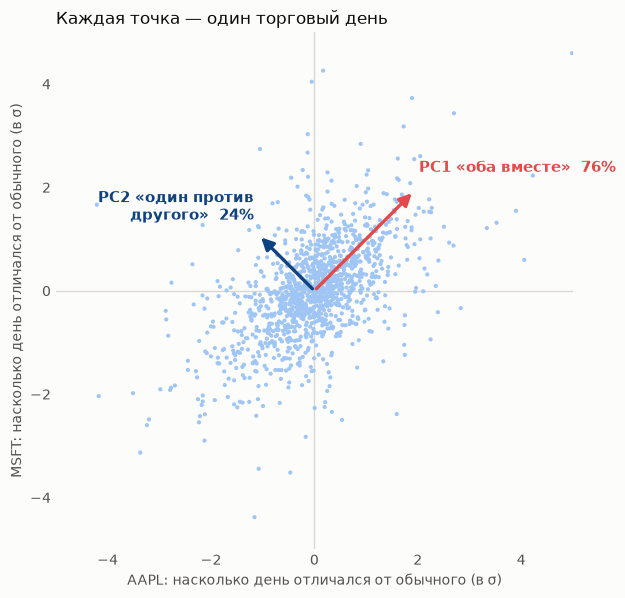

In [3]:
z = standardize(r[['AAPL', 'MSFT']])
lam2, Q2 = pca(z.cov())
print(f"ρ = {z.corr().iloc[0, 1]:.2f},  λ = {lam2.round(2).tolist()}")
pca_2d(z, lam2, Q2);

## PCA на 27 активах (корреляционная матрица)
Корреляции — чтобы «громкие» активы (NVDA, 52% годовой волатильности) не тянули факторы на себя.

In [4]:
lam, Q = pca(C)
print('QΛQᵀ = C:', np.allclose(Q.to_numpy() @ np.diag(lam) @ Q.to_numpy().T, C))
print('QᵀQ = I: ', np.allclose(Q.T @ Q, np.eye(27)))

Z = standardize(r).to_numpy()
s = np.linalg.svd(Z, compute_uv=False)
print('SVD: s²/(T−1) = λ:', np.allclose(s ** 2 / (len(Z) - 1), lam))

F = factor_returns(standardize(r), Q)
print('макс. |корреляция| между факторами:', np.abs(np.triu(F.corr().to_numpy(), 1)).max().round(6))

QΛQᵀ = C: True
QᵀQ = I:  True
SVD: s²/(T−1) = λ: True
макс. |корреляция| между факторами: 0.0


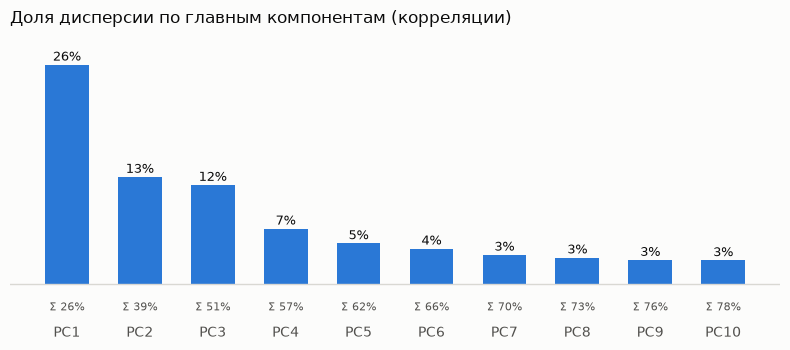

In [5]:
scree(explained_variance(lam), title='Доля дисперсии по главным компонентам (корреляции)');

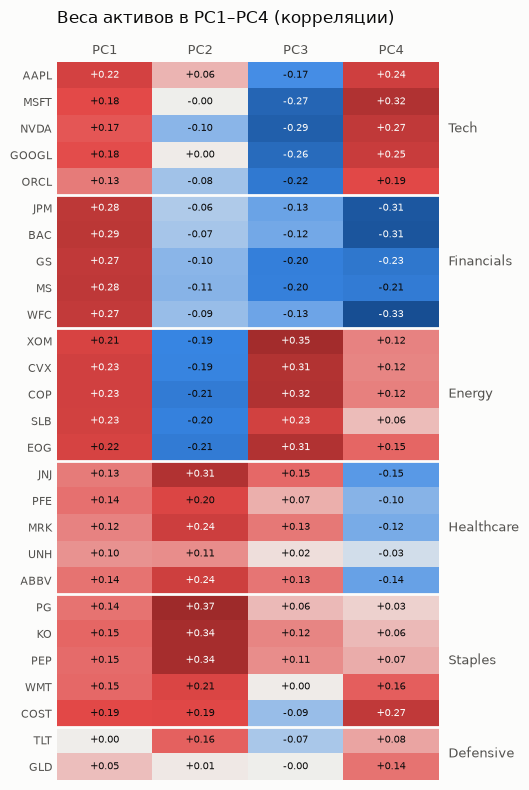

In [6]:
loadings_heatmap(Q.iloc[:, :4], UNIVERSE, 'Веса активов в PC1–PC4 (корреляции)');

| Фактор | Доля | Рецепт | Интерпретация |
|---|---|---|---|
| PC1 | 26% | все акции +, TLT ≈ 0 | **Рынок** |
| PC2 | 13% | Staples, Healthcare, TLT + / Energy − | **Защита против нефти** |
| PC3 | 12% | Energy + / Tech − | **Нефть против технологий** (value vs growth) |
| PC4 | 7% | Tech + / Financials − | **Техи против банков** |

Названия — наша интерпретация; структуру нашла линейная алгебра.

In [7]:
ew = r[TICKERS[:25]].mean(axis=1)
print(f'корреляция PC1 с равновзвешенным портфелем акций: {F.PC1.corr(ew):.3f}')
for pc in ['PC1', 'PC4']:
    for day in [F[pc].idxmax(), F[pc].idxmin()]:
        by_sector = {s: float(round(r.loc[day, t].mean() * 100, 1)) for s, t in UNIVERSE.items()}
        print(f'{pc} {day.date()}  F = {F.loc[day, pc]:+.1f}   {by_sector}')

корреляция PC1 с равновзвешенным портфелем акций: 0.988
PC1 2025-04-09  F = +21.3   {'Tech': 13.2, 'Financials': 8.8, 'Energy': 8.7, 'Healthcare': 2.9, 'Staples': 4.8, 'Defensive': 2.1}
PC1 2025-04-04  F = -18.7   {'Tech': -5.6, 'Financials': -7.5, 'Energy': -8.8, 'Healthcare': -5.1, 'Staples': -4.5, 'Defensive': -0.6}
PC4 2025-04-09  F = +5.3   {'Tech': 13.2, 'Financials': 8.8, 'Energy': 8.7, 'Healthcare': 2.9, 'Staples': 4.8, 'Defensive': 2.1}
PC4 2024-11-06  F = -7.2   {'Tech': 3.1, 'Financials': 11.6, 'Energy': 4.1, 'Healthcare': 0.3, 'Staples': -1.3, 'Defensive': -2.9}


## Сектора из одних чисел
Акции одного сектора получают одинаковый толчок от общего двигателя → движутся вместе → максимизация дисперсии захватывает их целыми группами с похожими весами. Значит, веса в PC2–PC4 работают как координаты, в которых сектора оказываются рядом.

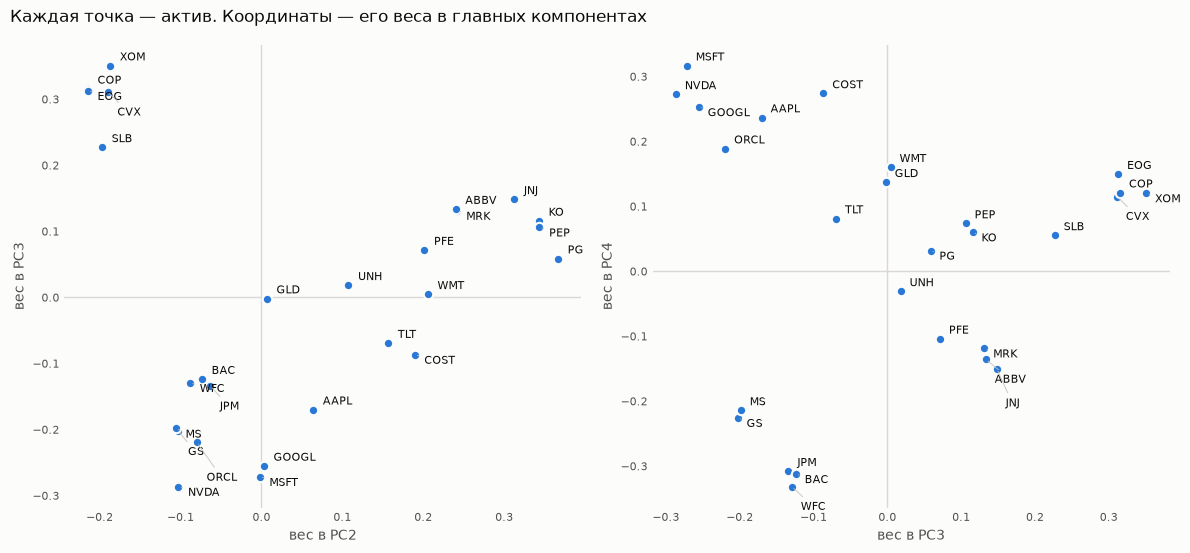

In [8]:
loadings_scatter(Q);

### Слепой тест
Перемешиваем порядок, стираем названия, запускаем PCA и группируем активы k-means по весам в PC2–PC5.

In [9]:
from scipy.cluster.vq import kmeans2

perm = np.random.default_rng(0).permutation(27)
anon = r.iloc[:, perm].copy()
anon.columns = [f'A{i}' for i in range(27)]
_, Qa = pca(anon.corr())
print('веса те же, только переставлены:', np.allclose(np.abs(Qa.to_numpy()[:, :5]), np.abs(Q.to_numpy()[perm, :5])))

coords = Qa.iloc[:, 1:5].to_numpy()
runs = [kmeans2(coords, 6, seed=s, minit='++') for s in range(20)]
centroids, labels = min(runs, key=lambda run: ((coords - run[0][run[1]]) ** 2).sum())

result = pd.DataFrame({'кластер': labels, 'тикер': r.columns[perm], 'сектор': [SECTOR_OF[t] for t in r.columns[perm]]})
result.groupby('кластер').agg(тикеры=('тикер', lambda x: ' '.join(sorted(x))), сектора=('сектор', lambda x: dict(x.value_counts())))

веса те же, только переставлены: True


,тикеры,сектора
кластер,,
0,AAPL GOOGL MSFT NVDA ORCL,{'Tech': 5}
1,COP CVX EOG SLB XOM,{'Energy': 5}
2,BAC GS JPM MS WFC,{'Financials': 5}
3,GLD TLT,{'Defensive': 2}
4,ABBV JNJ MRK PFE UNH,{'Healthcare': 5}
5,COST KO PEP PG WMT,{'Staples': 5}


**Оговорки:** число групп (6) мы подсказали; набор активов «учебный» (чистые сектора, крупные компании); PCA группирует по поведению, а не по бизнесу (COST по PC4 ближе к техам, UNH слабо связан со своим сектором).

## Ковариация вместо корреляции: эффект «громкого» актива

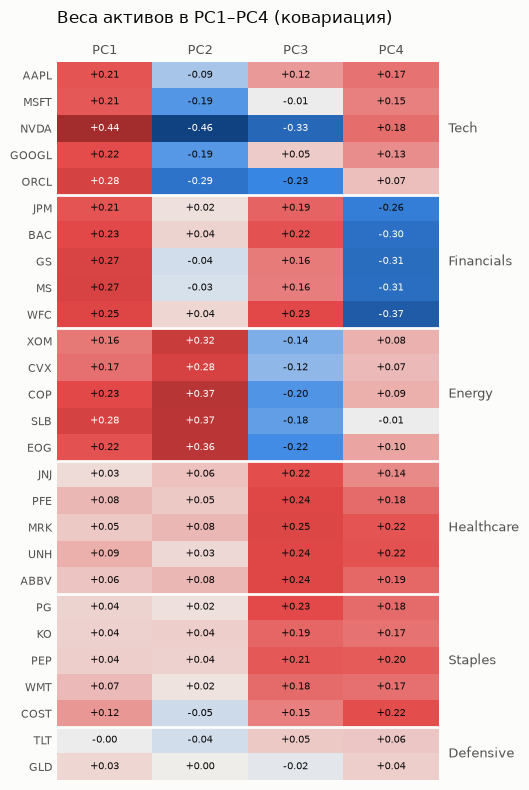

In [10]:
lam_cov, Q_cov = pca(S)
loadings_heatmap(Q_cov.iloc[:, :4], UNIVERSE, 'Веса активов в PC1–PC4 (ковариация)');

В PC1 у NVDA вес 0.44 — почти вдвое больше, чем у остальных: PCA на ковариации тянется к самым волатильным активам. Для интерпретации факторов используем корреляции, для риска в деньгах — ковариацию.

## Ограничения
- PCA линеен и ищет дисперсию, а не смысл.
- Знак собственного вектора произволен (фиксируем: сумма весов > 0).
- Факторы с близкими λ (PC2 = 12.7% и PC3 = 11.8%) неустойчивы: на другом периоде могут смешаться или поменяться местами.